In [1]:
# Experiment with Regularization Techniques
# o Train a model with and without L2 regularization.
# o Add Dropout and compare performance.
# o Visualize training/validation loss and accuracy.

In [2]:
# Import libraries
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

I0000 00:00:1794467165.183547    7279 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794467165.298411    7279 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794467170.923520    7279 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
# Load and preprocess MNIST using Pandas
train = pd.read_csv("dataset/Handwritten/mnist_train.csv")
test = pd.read_csv("dataset/Handwritten/mnist_test.csv")

x_train = train.iloc[:, 1:].values.astype('float32') / 255.0
y_train = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values.astype('float32') / 255.0
y_test = test.iloc[:, 0].values

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)
print("Missing values:", train.isnull().sum().sum())

Training data: (60000, 784)
Testing data: (10000, 784)
Missing values: 0


In [4]:
# Build and train three models
histories = []
results = []

for name in ['Normal', 'L2', 'Dropout']:

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(784,)),
        tf.keras.layers.Dense(128, activation='relu',
            kernel_regularizer=tf.keras.regularizers.l2(0.001) if name == 'L2' else None)
    ])

    if name == 'Dropout':
        model.add(tf.keras.layers.Dropout(0.5))

    model.add(tf.keras.layers.Dense(10, activation='softmax'))

    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    history = model.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

    loss, acc = model.evaluate(x_test, y_test, verbose=0)

    histories.append(history)
    results.append(acc)

    print(name, "Test Accuracy:", acc * 100, "%")

E0000 00:00:1794467221.513168    7279 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/5


W0000 00:00:1794467222.446624    7279 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.9094 - loss: 0.3217 - val_accuracy: 0.9617 - val_loss: 0.1430
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9577 - loss: 0.1449 - val_accuracy: 0.9695 - val_loss: 0.1067
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.9709 - loss: 0.1004 - val_accuracy: 0.9743 - val_loss: 0.0910
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9782 - loss: 0.0750 - val_accuracy: 0.9757 - val_loss: 0.0854
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.9831 - loss: 0.0573 - val_accuracy: 0.9775 - val_loss: 0.0773


W0000 00:00:1794467297.905033    7279 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


Normal Test Accuracy: 97.53000140190125 %
Epoch 1/5


W0000 00:00:1794467300.337156    7279 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.9100 - loss: 0.4417 - val_accuracy: 0.9560 - val_loss: 0.2605
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9509 - loss: 0.2582 - val_accuracy: 0.9638 - val_loss: 0.2094
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9609 - loss: 0.2134 - val_accuracy: 0.9708 - val_loss: 0.1798
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9659 - loss: 0.1930 - val_accuracy: 0.9712 - val_loss: 0.1755
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.9687 - loss: 0.1774 - val_accuracy: 0.9682 - val_loss: 0.1813
L2 Test Accuracy: 96.53000235557556 %
Epoch 1/5


W0000 00:00:1794467378.368714    7279 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.8612 - loss: 0.4627 - val_accuracy: 0.9538 - val_loss: 0.1599
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9264 - loss: 0.2503 - val_accuracy: 0.9677 - val_loss: 0.1202
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9399 - loss: 0.2049 - val_accuracy: 0.9723 - val_loss: 0.1031
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9458 - loss: 0.1805 - val_accuracy: 0.9748 - val_loss: 0.0932
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9519 - loss: 0.1611 - val_accuracy: 0.9747 - val_loss: 0.0863
Dropout Test Accuracy: 97.03999757766724 %


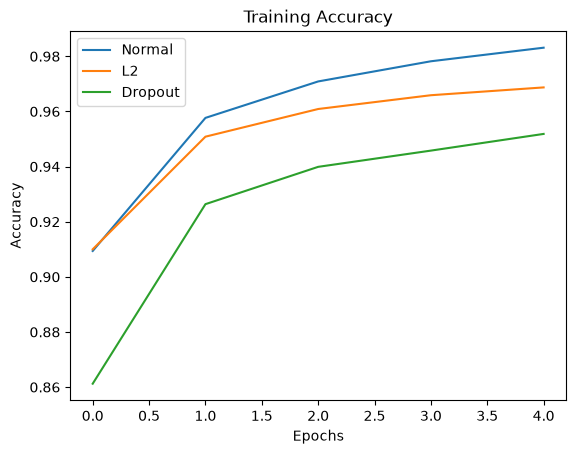

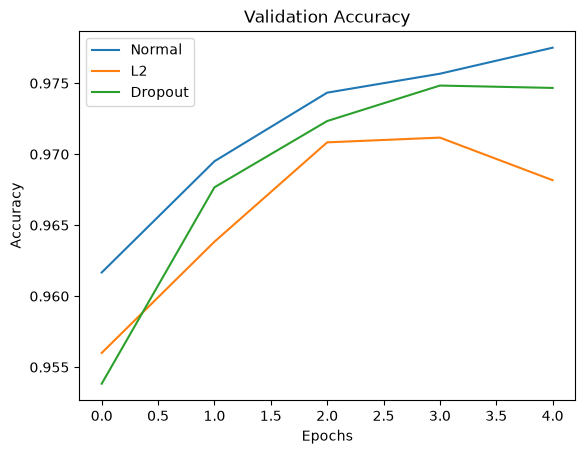

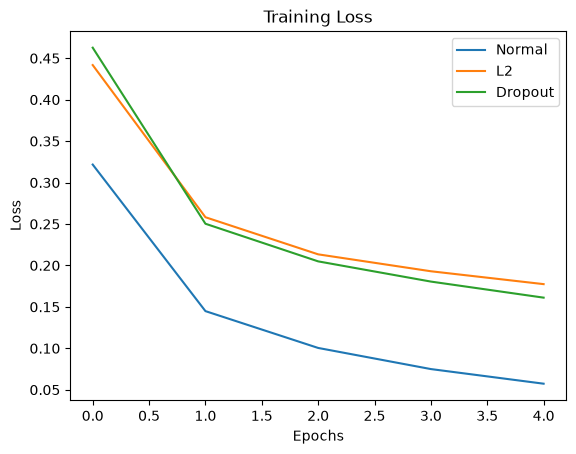

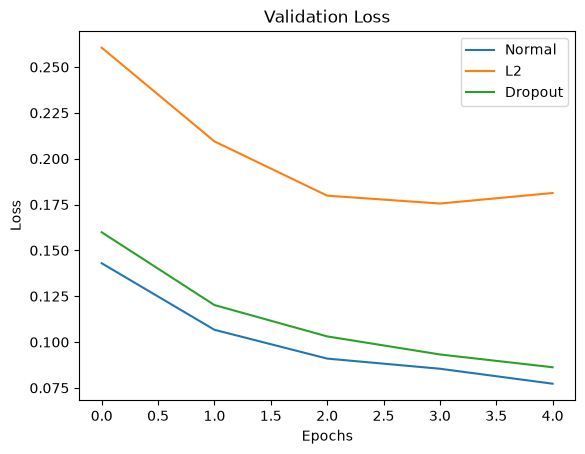

In [5]:
# Compare training and validation accuracy
for i, h in enumerate(histories):
    plt.plot(h.history['accuracy'], label=['Normal', 'L2', 'Dropout'][i])

plt.title("Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

for i, h in enumerate(histories):
    plt.plot(h.history['val_accuracy'], label=['Normal', 'L2', 'Dropout'][i])

plt.title("Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Compare training and validation loss
for i, h in enumerate(histories):
    plt.plot(h.history['loss'], label=['Normal', 'L2', 'Dropout'][i])

plt.title("Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

for i, h in enumerate(histories):
    plt.plot(h.history['val_loss'], label=['Normal', 'L2', 'Dropout'][i])

plt.title("Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()